![Banner](../../../../Images/Banner/03_spatial_analysis/03_05_banner_spatial_analysis_Network.png)



# Spatial Network Analysis



Places are connected. Roads join towns, commuters move between them, census tracts share borders, and farmers ask neighbours for advice. **Spatial network analysis** represents those connections as a graph whose nodes sit in geographic space, then measures routes, access, flows, neighbours, and the spread of people or ideas along the links.

This notebook is the conceptual map for the chapter. It explains what a spatial network is, the main types you will meet, and how `geolattice.spatial_analysis.network_analysis` carries those ideas into the five hands-on notebooks that follow. Every later notebook runs offline on the synthetic region in `Data/00_shared/data_spatial_net/` and imports that module as `sna`.

Six notebooks place a graph on a map and measure routes, neighbours, access, and flows.

- **Spatial Network Analysis.** This notebook. What a spatial network is, the main types, and the `sna` API.
- **Geographic Embedding of Nodes and Edges.** Coordinates and CRS, haversine and projected lengths, circuity, Kansky indices, and distance-based random graphs.
- **Road networks with OSMnx: Routing and Accessibility.** Speeds and travel times on the synthetic street graph, shortest paths, an origin-destination matrix, isochrones, and a road closure.
- **Building Networks from GeoPandas Data.** Contiguity, k-nearest neighbours, distance bands, Delaunay, Gabriel, and relative neighbourhood graphs, and lines turned into a graph.
- **Service-area and Facility Accessibility.** Nearest facility, service areas, population coverage, 2SFCA and E2SFCA, and a hospital closure.
- **Flow Networks: Commuting, Gravity, and Contagion.** A commuting origin-destination graph, gravity models, a dominant-flow hierarchy, functional regions, and a metapopulation SIR.

Library: `geolattice.spatial_analysis.network_analysis`


## Overview

A **network** is a set of **nodes** (also called vertices) joined by **edges** (also called links). A **spatial network** gives every node a location, and it gives every edge a geographic meaning: a road segment, a shared boundary, a volume of trips, or a social tie whose chance of existing falls with distance.

The same object appears under several names. Transport planners say *network*. Graph theory says *graph*. Spatial statistics says *weights matrix*. An origin-destination table is a flow network written as a matrix. All four are the same idea: who is connected to whom, and what that connection costs or carries.

Three ingredients turn an ordinary graph into a spatial one:

1. **Locations.** Each node has coordinates and a coordinate reference system (longitude/latitude, or a projected CRS such as a UTM zone).
2. **A connection rule.** Edges exist because a road was built, two polygons touch, two points fall inside a distance, or a survey recorded a tie.
3. **A weight.** The edge stores a length, a travel time, a count of commuters, or a binary "linked / not linked".

Once the graph exists, analysis is a shortest-path, a neighbour list, a flow balance, or a diffusion process on those weights. The map is how you read the result; the graph is how you compute it.

### A small vocabulary

| Term | Meaning in this chapter |
|---|---|
| **Node** | A junction, town, tract, hospital, or farmer |
| **Edge** | A road segment, shared border, trip, or advice tie |
| **Weight** | Length (km), travel time (minutes), or volume (commuters) |
| **Directed edge** | A one-way street, a commute from home to work, or "A seeks advice from B" |
| **Path** | A sequence of edges from an origin to a destination |
| **Component** | A set of nodes that can reach one another |
| **Embedding** | The coordinates that place the graph on the Earth |
| **Impedance** | The cost minimised by a route (distance or time) |


## Measuring a spatial network

### Length and travel time

Edge length has to respect the CRS.

- On **longitude/latitude**, length is the **haversine** (great-circle) distance. One degree of longitude is shorter than one degree of latitude, so treating degrees as flat x/y stretches east-west distances.
- On a **projected metric CRS** (metres), length is ordinary Euclidean distance between the endpoints.

Travel time then follows from length and speed:

$$t = \frac{\text{length}}{\text{speed}}$$

OSMnx fills speeds from the highway class (or from an observed `maxspeed` tag) and stores `travel_time` in seconds. Shortest-distance routes and shortest-time routes diverge wherever fast roads are longer than slow ones.

### Circuity

**Circuity** compares the route you can actually travel with the straight line between the same two points:

$$\text{circuity} = \frac{\text{network distance}}{\text{straight-line distance}}$$

A value of 1 is a perfectly direct link. Urban street grids often fall around 1.2-1.4; mountainous or river-cut regions run higher. Circuity is why a 5 km buffer around a hospital overstates who can reach it: people travel along roads.

### How connected is the network?

**Kansky indices** summarise a planar network with three ratios. With \(v\) nodes, \(e\) edges, and \(p\) components:

$$
\beta = \frac{e}{v}, \qquad
\alpha = \frac{e - v + p}{2v - 5}, \qquad
\gamma = \frac{e}{3(v - 2)}
$$

- **β** is the average number of edges per node. A tree has β just under 1; a dense street grid is higher.
- **α** (the redundancy index) is the share of the maximum number of *cycles* a planar graph can hold. α near 0 is a branching tree; α near 1 is as looped as a planar graph can be.
- **γ** is the share of the maximum number of *edges* in a connected planar graph.

Alongside those indices, a description of a spatial graph usually reports the number of components, the share of nodes in the largest component, average clustering, and mean path length. A road network that looks connected on a map can still have a bridge whose removal splits it in two.

### Distance decay

Across roads, trips, and social ties, interaction thins out as separation grows. A **random geometric graph** links every pair of points closer than a threshold. A **Waxman** graph links them with probability

$$P(\text{link}) \propto \exp(-d / d_0)$$

Empirical link rates, the chance two tracts touch, two towns exchange commuters, or two farmers name each other, follow the same shape. Distance decay is the reason a neighbour graph, a gravity model, and an advice network belong in one chapter.


## Types of spatial networks

The connection rule, more than the software, decides which network you have. This chapter works through four types. The same GeoLattice functions serve all of them; what changes is how edges are defined.

| Type | Nodes | Edges | Weight | Leading question |
|---|---|---|---|---|
| **Transportation and infrastructure** | Junctions, stops, towns | Road, rail, pipe, or stream segments | Length, minutes | What is the best route, and who is cut off if a link fails? |
| **Proximity and contiguity** | Polygons or points | Shared border, or nearness in space | Binary, or inverse distance | Who counts as a neighbour? |
| **Flow and interaction** | Places or zones | Origin-destination pairs | Trips, tonnes, migrants | Where does volume go, and which places form a region? |
| **Spatially embedded social networks** | People, farms, firms | Advice, kinship, collaboration | Binary or frequency | Who should be reached first so something spreads? |

### Transportation and infrastructure networks

Edges are physical objects. A street, a rail line, a water main, or a channel is a linestring with a length. Nodes are intersections, stops, or the places snapped onto that network. These graphs are embedded: you can draw every edge on a map, and most of them are planar or nearly so (bridges and tunnels are the usual exceptions).

Typical products:

- a shortest path by distance or by time
- an origin-destination matrix of travel times
- an **isochrone**, the set of nodes reachable within 10, 20, or 30 minutes
- the edges whose removal adds the most travel time (a closure scenario)

Notebooks [03_06_01](03_05_01_geographic_embedding.ipynb) and [03_06_02](03_05_02_osmnx_routing.ipynb) build this type. [03_06_04](03_05_04_service_area_access.ipynb) uses the same road graph to measure access to hospitals.

### Proximity and contiguity networks

Many GIS layers have no built links. Counties, tracts, farms, and sample points become a network only after you choose a neighbour rule.

| Rule | Two units are linked when… | Geometry |
|---|---|---|
| **Rook** | They share a boundary of positive length | Polygons |
| **Queen** | They share any point, including a corner | Polygons |
| **k-nearest neighbours** | One is among the *k* closest of the other | Points |
| **Distance band** | They lie inside a threshold distance | Points |
| **Delaunay** | Their Voronoi cells touch | Points |
| **Gabriel / relative neighbourhood (RNG)** | The empty-region test of that graph family holds | Points |
| **Shared endpoints** | Line ends meet, after snapping | Lines |

Rook and Queen are the standard contiguity rules for a spatial weights matrix \(W\). Queen has at least as many links as Rook; on a regular grid the corner contacts are the difference. k-NN graphs keep every unit connected (each has *k* neighbours) and are directed until you symmetrise them. A distance band can leave **islands**, units with no neighbour, until the threshold reaches the minimum that connects the nearest isolated pair.

These graphs are the neighbour structure for spatial lag, Moran's *I*, and regionalisation. Notebook [03_06_03](03_05_03_geopandas_networks.ipynb) builds all of them from a GeoDataFrame with libpysal.

### Flow and interaction networks

A **flow network** records movement between places. The natural storage is an origin-destination (OD) table: one row per pair, with a volume. As a graph, the same table is directed and weighted. The edge *i → j* carries commuters, freight, migrants, or trade, and it is a different edge from *j → i*.

Standard summaries:

- **inflow, outflow, and net flow** at each place
- a **gravity model**, which predicts volume from the size of the two places and the cost of separating them

$$F_{ij} = k \, O_i^{\alpha} \, D_j^{\beta} \, c_{ij}^{\gamma}$$

Here \(O_i\) and \(D_j\) are origin and destination mass (population, jobs), \(c_{ij}\) is impedance (minutes or kilometres), and \(\gamma\) is negative: longer separations carry less flow. The chapter fits this both by ordinary least squares on the logarithms and by Poisson pseudo-maximum likelihood (PPML), which keeps the zero flows that a log transform drops.

- a **dominant-flow hierarchy** (Nystuen-Dacey): each place points to the larger place that receives its single biggest outflow, which draws a tree of central places
- **functional regions** from community detection on the symmetrised flows
- a **metapopulation** model in which infection (or information) moves with the commuting matrix

Notebook [03_06_05](03_05_05_flow_networks.ipynb) works this type on a synthetic commuting table, with travel time taken from the road network.

### Spatially embedded social networks

People and organisations have coordinates too. An advice network, a kinship network, or a collaboration network is spatial when ties are more common at short distances and still exist, more rarely, across long ones. The edges are choices, recorded in a survey or inferred from interaction, and direction matters: if farmer *i* seeks advice from farmer *j*, information flows from *j* to *i*. **In-degree** (how often someone is named) is a simple measure of opinion leadership.

Two diffusion rules sit on the same adjacency matrix:

- **Simple contagion.** One contact with an adopter is enough to adopt. Disease and many rumours behave this way.
- **Complex contagion.** Adoption needs several adopting neighbours. Practices that are costly, unfamiliar, or socially risky often behave this way, so a single well-connected outsider may fail to spark a village while a pair of local leaders succeeds.

Distance still structures the graph: most ties stay inside a village, and a few bridges join villages. Those bridges, and farmers with high **participation** (ties spread across communities) or high **diffusion centrality**, are the people an extension service wants to train. Notebook [03_06_06](../03_08_capston/03_08_06_farmer_networks_case_study.ipynb) is the case study.


## Applications

The type of network follows the decision. The table pairs common questions with the notebook that works the method.

| Domain | Question the analysis answers | Type | Notebook |
|---|---|---|---|
| Transport | Which route is shortest in kilometres, and which is shortest in minutes? | Transportation | [03_06_02](03_05_02_osmnx_routing.ipynb) |
| Transport | How much longer are real routes than the straight line? | Transportation | [03_06_01](03_05_01_geographic_embedding.ipynb) |
| Resilience | If this segment closes, how do town-to-town times change? | Transportation | [03_06_02](03_05_02_osmnx_routing.ipynb) |
| Health access | What is the drive time from every tract to the nearest hospital? | Transportation | [03_06_04](03_05_04_service_area_access.ipynb) |
| Health access | What share of the population, and of people aged 65+, lives within 15 or 30 minutes? | Transportation | [03_06_04](03_05_04_service_area_access.ipynb) |
| Health equity | Where is supply per person high, once competition from other tracts is counted? | Transportation | [03_06_04](03_05_04_service_area_access.ipynb) |
| Siting | Which extra clinic reduces population-weighted travel time the most? | Transportation | [03_06_04](03_05_04_service_area_access.ipynb) |
| Spatial statistics | Which tracts are neighbours for a spatial lag or Moran's *I*? | Contiguity | [03_06_03](03_05_03_geopandas_networks.ipynb) |
| Hydrology and utilities | How do line features become a routable graph? | Infrastructure | [03_06_03](03_05_03_geopandas_networks.ipynb) |
| Regional science | Does a gravity model reproduce the commuting pattern? | Flow | [03_06_05](03_05_05_flow_networks.ipynb) |
| Regional science | Which town is the centre of a commuting hierarchy? | Flow | [03_06_05](03_05_05_flow_networks.ipynb) |
| Epidemiology | How fast does infection move between towns that exchange workers? | Flow | [03_06_05](03_05_05_flow_networks.ipynb) |
| Agricultural extension | Which farmers, if trained, spread a practice through the advice network? | Social | [03_06_06](../03_08_capston/03_08_06_farmer_networks_case_study.ipynb) |

### Accessibility in one formula

Service-area work in this chapter uses the **two-step floating catchment area** (2SFCA). Supply at facility \(j\) is shared across the demand that can reach it, then each demand location \(i\) sums the supply ratios it can reach:

$$
R_j = \frac{S_j}{\sum_k P_k \, W(d_{kj})}, \qquad
A_i = \sum_j R_j \, W(d_{ij})
$$

\(S_j\) is supply (beds, clinics), \(P_k\) is demand (population), and \(d\) is network time. In classic 2SFCA the weight \(W\) is 1 inside a time threshold and 0 outside. **Enhanced 2SFCA** replaces that step with a smooth decay, such as a Gaussian, so a facility 5 minutes away counts more than one 25 minutes away. A Lorenz curve and a Gini coefficient then show whether those scores are shared evenly across the population.

The same travel times feed location-allocation sketches: the **p-median** idea (place facilities to reduce population-weighted travel time) and **maximal coverage** (place them so more people fall inside a time budget).


## A workflow that fits every type

```
+----------------------------------------------------------------------+
|  1. STATE THE QUESTION AND THE NODES                                |
|     Routes, neighbours, flows, or diffusion?                         |
|     Junctions, zones, facilities, or people?                         |
+---------------------------+------------------------------------------+
                            |
                            v
+----------------------------------------------------------------------+
|  2. CHOOSE THE CONNECTION RULE                                      |
|     Physical links  |  contiguity / k-NN / distance  |  OD table    |
|     or a recorded social tie                                         |
+---------------------------+------------------------------------------+
                            |
                            v
+----------------------------------------------------------------------+
|  3. SET THE CRS AND THE WEIGHT                                      |
|     Haversine or a projected CRS for length; speed to travel time;  |
|     volume for flows; binary or distance-decay for social ties      |
+---------------------------+------------------------------------------+
                            |
                            v
+----------------------------------------------------------------------+
|  4. DESCRIBE THE GRAPH                                              |
|     Components, degree, circuity, Kansky α/β/γ, distance decay      |
+---------------------------+------------------------------------------+
                            |
                            v
+----------------------------------------------------------------------+
|  5. COMPUTE THE QUANTITY THE QUESTION ASKS FOR                     |
|     Shortest paths, isochrones, 2SFCA, gravity fit, communities,    |
|     or a contagion run                                               |
+---------------------------+------------------------------------------+
                            |
                            v
+----------------------------------------------------------------------+
|  6. MAP A SCENARIO                                                  |
|     A closed road, a new clinic, a different neighbour rule,        |
|     or a different set of people trained first                      |
+----------------------------------------------------------------------+
```

Steps 1-3 are the modelling choices. Steps 4-6 are what the notebooks compute. Changing the neighbour rule or the time threshold and watching the map change is part of the analysis, in the same spirit as a sensitivity test in suitability modelling.


## Network analysis with GeoLattice

The hands-on notebooks call one module:

```python
from geolattice.spatial_analysis import network_analysis as sna
```

Graphs are NetworkX objects (`Graph`, `DiGraph`, or `MultiDiGraph`). Road networks are OSMnx graphs stored as GraphML. Polygon and point neighbours are libpysal weights converted to NetworkX. Tables of places and flows stay in GeoPandas and pandas, so a result can be mapped with the same `.plot` calls as the rest of this course.

Optional libraries load only when a function needs them. Install the set used in this chapter with:

```bash
pip install networkx geopandas osmnx libpysal scikit-learn
```

or, when the optional extra is available:

```bash
pip install "geolattice[network]"
```

`matplotlib`, `numpy`, and `pandas` are already assumed.

### Geographic embedding: notebook 01

| Function | What it does |
|---|---|
| `haversine_km(lon1, lat1, lon2, lat2)` | Great-circle distance in kilometres |
| `graph_positions(G)` | `{node: (x, y)}` from node attributes |
| `set_edge_lengths_haversine(G)` | Edge lengths from lon/lat via haversine |
| `set_edge_lengths_euclidean(G)` | Edge lengths from projected coordinates |
| `kansky_indices(G)` | Planar α, β, γ plus node and edge counts |
| `graph_component_summary(G)` | Clustering, largest-component share, mean path length |
| `describe_spatial_graph(G, pos)` | Degree, components, and link-length summary |
| `link_probability_by_distance(G, pos, bins)` | Empirical probability of an edge by distance bin |
| `circuity_sample(G, n_pairs)` | Network distance, straight-line distance, and circuity |
| `is_planar_graph(G)` | Whether the undirected graph is planar |

### Routing on a street network: notebook 02

| Function | What it does |
|---|---|
| `load_road_graph(path)` | Read an OSMnx-compatible GraphML file |
| `prepare_travel_times(G)` | Add edge speeds and travel times |
| `snap_points_to_nodes(gdf, G)` | Nearest network node for each point |
| `shortest_routes(G, origin, destination)` | Shortest paths for one or more edge weights |
| `route_summary(G, route)` | Kilometres, minutes, and highway mix along a route |
| `od_travel_time_matrix(G, places)` | Place-by-place travel-time matrix |
| `isochrone_polygons(G, center, budgets_min)` | Polygons reachable within each time budget |
| `cumulative_accessibility(G, opportunities)` | Opportunity mass reachable within a cutoff |
| `edge_travel_time_betweenness(G)` | Sampled travel-time betweenness on edges |
| `closure_impact(G, edges_to_remove, places)` | Change in OD times after edges are removed |

The same steps run on a live OpenStreetMap extract (`ox.graph_from_place`, `ox.graph_from_point`, or `ox.graph_from_bbox`). The notebook shows that download, then continues offline so the chapter stays reproducible.

### Networks from GeoPandas layers: notebook 03

| Function | What it does |
|---|---|
| `build_spatial_graphs(gdf)` | Queen, rook, k-NN, distance band, Delaunay, Gabriel, and RNG |
| `weights_to_graph(W, labels)` | libpysal weights object to a NetworkX graph |
| `min_threshold_distance(xy)` | Smallest distance band with no islands |
| `percolation_curve(xy, thresholds)` | Largest component and mean degree as the band grows |
| `row_standardize(W)` | Row-standardised adjacency |
| `spatial_lag(y, Wr)` | Spatial lag \(W y\) |
| `morans_i(y, Wr)` | Moran's *I* on a row-standardised matrix |
| `lines_to_graph(gdf)` | Undirected graph from lines that share endpoints |
| `similarity_weighted_communities(G, attrs)` | Louvain communities with attribute-weighted edges |

### Service areas and accessibility: notebook 04

| Function | What it does |
|---|---|
| `nearest_facility_network(G, demand, facilities)` | Multi-source Dijkstra: time and nearest facility |
| `nearest_facility_euclidean(demand, facilities)` | Straight-line nearest facility, for comparison |
| `travel_time_matrix(G, origins, destinations)` | Origin-by-destination times, with optional access legs |
| `population_coverage(df)` | Share of each population column inside time thresholds |
| `gaussian_distance_decay(t, d0)` | Gaussian weights for enhanced 2SFCA |
| `two_sfca(T, P, S)` | Classic or decay-weighted 2SFCA scores |
| `lorenz_curve_gini(values, weights)` | Population-weighted Lorenz curve and Gini coefficient |
| `evaluate_candidate_sites(...)` | Population-weighted time and coverage gain of each candidate |

### Flow networks: notebook 05

| Function | What it does |
|---|---|
| `od_to_digraph(od)` | Directed weighted graph from an OD table |
| `node_flow_balance(G)` | Inflow, outflow, net flow, and in/out ratio |
| `attach_od_impedance(od, G, places)` | Network minutes (and optional Euclidean km) on each OD row |
| `fit_gravity_model(od, method)` | Gravity model by OLS-on-log or PPML |
| `pseudo_r2(y, yhat)` | Squared correlation as a fit diagnostic |
| `dominant_flow_hierarchy(od, populations)` | Nystuen-Dacey tree and central places |
| `symmetric_flow_graph(od)` | Undirected graph for community detection |
| `flow_communities(od)` | Louvain regions and modularity |
| `flow_pagerank(G)` | Attraction rank from weighted PageRank |
| `metapopulation_sir(C, N, seed)` | Commuting-coupled SIR prevalence over time |
| `arrival_times(H)` | First time each place crosses a prevalence threshold |

### Farmer advice networks: notebook 06

| Function | What it does |
|---|---|
| `graph_from_edgelist(ties, nodes)` | Graph from an edge list, with node attributes |
| `pairwise_distance_matrix(gdf)` | Euclidean distances between point geometries |
| `tie_distance_decay(pairs_km, ties)` | Probability of a tie against distance |
| `participation_coefficient(G, communities)` | How evenly a node's ties cross communities |
| `diffusion_centrality(A)` | Finite-horizon diffusion centrality |
| `community_label_agreement(a, b)` | Adjusted Rand index between two labelings |
| `select_seeds(nodes, strategy, k)` | *k* seeds: random, extension contact, in-degree, leaders, bridges |
| `simulate_contagion(A, seeds, model)` | Simple or complex contagion on an adjacency matrix |
| `monte_carlo_contagion(...)` | Repeated seeding; adoption curves and arrival times |


## The synthetic region

Every notebook in the chapter reads `Data/00_shared/data_spatial_net/`. The files are synthetic, so the chapter runs without a network connection and the same code path accepts a real OSMnx download.

| File | Contents |
|---|---|
| `roads.graphml` | Driveable road graph |
| `towns.geojson` | Town points used as routing and flow places |
| `hospitals.geojson` | Facility points |
| `tracts.geojson` | Population polygons (demand and contiguity) |
| `study_area.geojson` | Study-area boundary |
| `commuting_od.csv` | Origin-destination commuting volumes |
| `town_travel_time_min.csv` | Town-to-town travel times |
| `farmers.geojson` | Farmer locations and attributes |
| `farmer_ties.csv` | Directed advice ties |

The goal of the data is to learn the methods. Counts, speeds, and the facility list are illustrative.


## The four types, drawn small

The next cell draws a schematic of each type. Edges in the transportation panel are street segments; the dashed line is the straight-line comparison used for circuity. The contiguity panel links tract centroids that share a border. The flow panel draws commuting arrows, with width proportional to volume. The social panel clusters advice ties inside villages and keeps a few bridges between them.


**Installation.** This notebook needs installation option 1 (vector, raster, CRS and visualization): `pip install "geolattice[core]"`. See "Installation options" in the GeoLattice README.

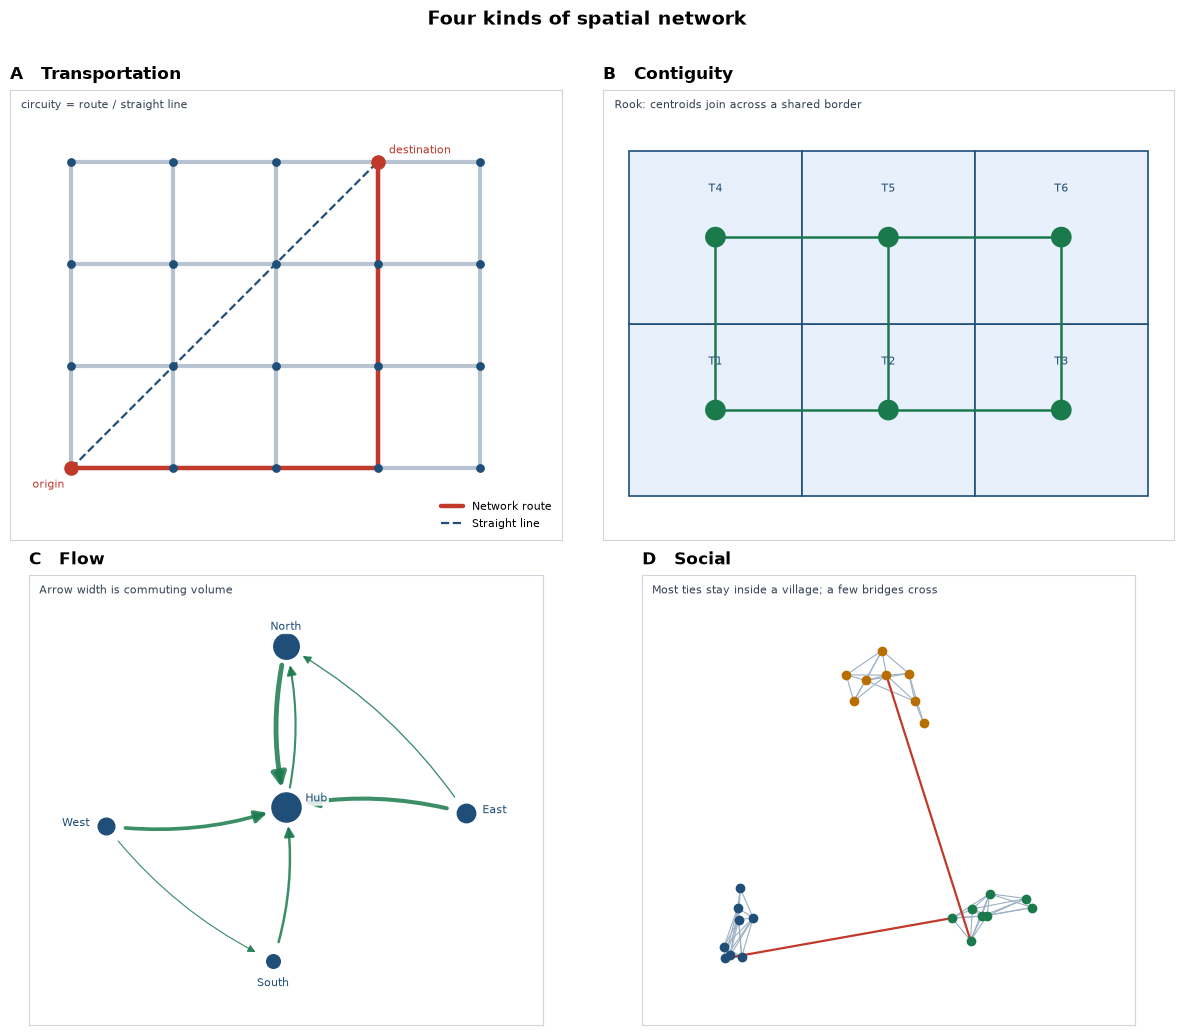

In [1]:
# Display matplotlib figures inline in this Jupyter notebook.
%matplotlib inline

# Numeric and plotting stack for the four schematic panels.
import numpy as np  # random village points and array arithmetic
import matplotlib.pyplot as plt  # figure and axes for the 2x2 schematic
from matplotlib.patches import FancyArrowPatch, Rectangle, Circle  # arrows, tracts, nodes

# Fixed seed so the social-panel village scatter is reproducible.
rng = np.random.default_rng(7)  # reproducible random generator

# ===================================================================
# Draw a 2x2 schematic of the four spatial network types used in this
# chapter: transportation, contiguity, flow, and social embedding.
# ===================================================================

# Create a 2x2 grid of axes for the four network-type panels.
fig, axes = plt.subplots(2, 2, figsize=(12.2, 10.2))  # create a grid of subplot axes


def style(ax, title):
    """Apply a shared title, hide ticks, and lighten spines for schematic panels."""
    ax.set_title(title, loc="left", fontweight="bold", fontsize=12, pad=8)  # left-aligned panel title
    ax.set_xticks([])  # hide x tick labels on schematic axes
    ax.set_yticks([])  # hide y tick labels on schematic axes
    for spine in ax.spines.values():  # iterate over the collection
        spine.set_color("#d0d5dd")  # soft grey frame around each panel
    ax.set_aspect("equal")  # keep street / tract geometry undistorted


# --- A. Transportation: street grid, route, and straight line -------------
ax = axes[0, 0]  # top-left panel
cols, rows = np.arange(5), np.arange(4)  # 5 vertical and 4 horizontal grid lines
# Draw horizontal street segments across each row.
for y in rows:  # iterate over the collection
    ax.plot([cols[0], cols[-1]], [y, y], color="#b7c3d0", lw=3, zorder=1, solid_capstyle="round")  # draw lines or edges on the axes
# Draw vertical street segments across each column.
for x in cols:  # iterate over the collection
    ax.plot([x, x], [rows[0], rows[-1]], color="#b7c3d0", lw=3, zorder=1, solid_capstyle="round")  # draw lines or edges on the axes

# Network route that follows the grid from origin to destination.
route = [(0, 0), (1, 0), (2, 0), (3, 0), (3, 1), (3, 2), (3, 3)]  # ordered route vertices for the schematic
rx, ry = zip(*route)  # unzip route vertices into x and y sequences
ax.plot(rx, ry, color="#c0392b", lw=3.2, zorder=2, solid_capstyle="round", label="Network route")  # draw lines or edges on the axes
# Straight-line chord used in the circuity ratio (network / Euclidean).
ax.plot([0, 3], [0, 3], color="#1f4e79", lw=1.6, ls="--", zorder=2, label="Straight line")  # draw lines or edges on the axes
# Scatter all grid junctions as small nodes.
ax.scatter(cols.repeat(len(rows)), np.tile(rows, len(cols)), s=28, c="#1f4e79", zorder=3)  # plot point markers
# Highlight origin and destination nodes.
ax.scatter([0, 3], [0, 3], s=90, c="#c0392b", zorder=4)  # plot point markers
ax.annotate("origin", (0, 0), textcoords="offset points", xytext=(-28, -14), fontsize=8, color="#c0392b")  # label a feature near its coordinates
ax.annotate("destination", (3, 3), textcoords="offset points", xytext=(8, 6), fontsize=8, color="#c0392b")  # label a feature near its coordinates
# Caption explaining the circuity definition shown in the panel.
ax.text(0.02, 0.98, "circuity = route / straight line", transform=ax.transAxes,  # caption or note in axes / figure coordinates
        va="top", fontsize=8, color="#344054")  # vertical alignment
ax.legend(frameon=False, fontsize=8, loc="lower right")  # route vs straight-line legend
ax.set_xlim(-0.6, 4.8)  # pad around the street grid
ax.set_ylim(-0.7, 3.7)  # pad or zoom the y extent
style(ax, "A   Transportation")  # apply shared schematic panel styling

# --- B. Contiguity: tracts and shared borders -----------------------------
ax = axes[0, 1]  # top-right panel
nrow, ncol = 2, 3  # 2x3 tract grid
# Draw tract polygons and label each cell.
for i in range(nrow):  # loop over an integer range
    for j in range(ncol):  # loop over an integer range
        ax.add_patch(Rectangle((j, i), 1, 1, facecolor="#e8f1fb", edgecolor="#1f4e79", lw=1.2))  # add a shape / arrow patch to the axes
        ax.text(j + 0.5, i + 0.78, f"T{i * ncol + j + 1}", ha="center", va="center", fontsize=8, color="#1f4e79")  # caption or note in axes / figure coordinates

def centroid(i, j):
    """Return the centroid (x, y) of tract cell (row i, column j)."""
    return j + 0.5, i + 0.5  # return the computed result

# Rook neighbours: draw an edge only when two tracts share a full border.
for i in range(nrow):  # loop over an integer range
    for j in range(ncol):  # loop over an integer range
        for di, dj in ((0, 1), (1, 0)):  # right neighbour and upper neighbour
            ni, nj = i + di, j + dj  # notebook step
            if ni < nrow and nj < ncol:  # conditional branch
                x0, y0 = centroid(i, j)  # run this analysis or plotting step
                x1, y1 = centroid(ni, nj)  # run this analysis or plotting step
                ax.plot([x0, x1], [y0, y1], color="#1a7a4c", lw=1.8, zorder=2)  # draw lines or edges on the axes
# Plot tract centroids as graph nodes.
for i in range(nrow):  # loop over an integer range
    for j in range(ncol):  # loop over an integer range
        ax.add_patch(Circle(centroid(i, j), 0.06, facecolor="#1a7a4c", edgecolor="none", zorder=3))  # add a shape / arrow patch to the axes
ax.text(0.02, 0.98, "Rook: centroids join across a shared border", transform=ax.transAxes,  # caption or note in axes / figure coordinates
        va="top", fontsize=8, color="#344054")  # vertical alignment
ax.set_xlim(-0.15, 3.15)  # pad or zoom the x extent
ax.set_ylim(-0.25, 2.35)  # pad or zoom the y extent
style(ax, "B   Contiguity")  # apply shared schematic panel styling

# --- C. Flow: commuting arrows --------------------------------------------
ax = axes[1, 0]  # bottom-left panel
# Town locations (x, y) and marker size proxy (population).
towns = {  # schematic town locations and sizes
    "North": (1.6, 2.6, 42),  # continue multi-line call
    "West": (0.2, 1.2, 18),  # continue multi-line call
    "East": (3.0, 1.3, 22),  # continue multi-line call
    "South": (1.5, 0.15, 12),  # continue multi-line call
    "Hub": (1.6, 1.35, 55),  # continue multi-line call
}
# Directed commuting volumes (origin, destination, volume).
flows = [  # town in-/out-/net-flow balance table
    ("West", "Hub", 8),  # continue multi-line call
    ("East", "Hub", 9),  # continue multi-line call
    ("South", "Hub", 5),  # continue multi-line call
    ("North", "Hub", 11),  # continue multi-line call
    ("Hub", "North", 4),  # continue multi-line call
    ("West", "South", 1.5),  # continue multi-line call
    ("East", "North", 2),  # continue multi-line call
]
# Draw each OD flow as an arrow whose width scales with volume.
for a, b, vol in flows:  # iterate over the collection
    x0, y0, _ = towns[a]  # notebook step
    x1, y1, _ = towns[b]  # notebook step
    ax.add_patch(FancyArrowPatch(  # add a shape / arrow patch to the axes
        (x0, y0), (x1, y1),  # origin and destination coordinates
        arrowstyle="-|>",  # filled arrow head
        mutation_scale=10 + vol,  # head size grows with volume
        lw=0.4 + 0.28 * vol,  # stroke width proportional to volume
        color="#1a7a4c",  # artist colour
        alpha=0.85,  # regularisation strength (0 = unpenalised PPML)
        connectionstyle="arc3,rad=0.12",  # slight curve so overlapping OD pairs separate
        shrinkA=14, shrinkB=14,  # keep arrow tips clear of town markers
    ))
# Offset each town label so it does not cover the marker.
label_at = {  # label offsets so text clears markers
    "North": (0, 14, "center"),  # continue multi-line call
    "West": (-12, 2, "right"),  # continue multi-line call
    "East": (12, 2, "left"),  # continue multi-line call
    "South": (0, -16, "center"),  # continue multi-line call
    "Hub": (14, 6, "left"),  # continue multi-line call
}
for name, (x, y, pop) in towns.items():  # iterate key/value pairs
    ax.scatter([x], [y], s=8 * pop, c="#1f4e79", zorder=3)  # marker area scales with population
    dx, dy, ha = label_at[name]  # notebook step
    ax.annotate(name, (x, y), textcoords="offset points", xytext=(dx, dy),  # label a feature near its coordinates
                ha=ha, va="center", fontsize=8, color="#1f4e79",  # horizontal alignment
                bbox=dict(boxstyle="round,pad=0.15", fc="white", ec="none", alpha=0.85))  # bbox argument
ax.text(0.02, 0.98, "Arrow width is commuting volume", transform=ax.transAxes,  # caption or note in axes / figure coordinates
        va="top", fontsize=8, color="#344054")  # vertical alignment
ax.set_xlim(-0.4, 3.6)  # pad or zoom the x extent
ax.set_ylim(-0.35, 3.15)  # pad or zoom the y extent
style(ax, "C   Flow")  # apply shared schematic panel styling

# --- D. Social: villages, local ties, bridges -----------------------------
ax = axes[1, 1]  # bottom-right panel
centers = np.array([[0.0, 0.0], [2.7, 0.25], [1.35, 2.35]])  # three village centres
village_color = ["#1f4e79", "#1a7a4c", "#b86e00"]  # one colour per village
points = []  # will hold the farmer point clouds
# Scatter farmers around each village and link nearby pairs (local ties).
for c, col in zip(centers, village_color):  # iterate paired sequences together
    pts = c + rng.normal(scale=0.28, size=(8, 2))  # 8 farmers per village
    points.append(pts)  # append this record
    for i in range(len(pts)):  # loop over an integer range
        for j in range(i + 1, len(pts)):  # loop over an integer range
            if np.hypot(*(pts[i] - pts[j])) < 0.55:  # link only close farmers
                ax.plot([pts[i, 0], pts[j, 0]], [pts[i, 1], pts[j, 1]],  # draw lines or edges on the axes
                        color="#9bb0c3", lw=0.8, zorder=1)  # artist colour
# Two between-village bridges that let practices leave a village.
bridges = [(points[0][2], points[1][5]), (points[1][1], points[2][4])]  # between-village bridge endpoints
for p, q in bridges:  # iterate over the collection
    ax.plot([p[0], q[0]], [p[1], q[1]], color="#c0392b", lw=1.6, zorder=2)  # draw lines or edges on the axes
# Plot farmers coloured by village membership.
for pts, col in zip(points, village_color):  # iterate paired sequences together
    ax.scatter(pts[:, 0], pts[:, 1], s=36, c=col, zorder=3)  # plot point markers
ax.text(0.02, 0.98, "Most ties stay inside a village; a few bridges cross",  # caption or note in axes / figure coordinates
        transform=ax.transAxes, va="top", fontsize=8, color="#344054")  # coordinate transform for text placement
ax.set_xlim(-0.9, 3.7)  # pad or zoom the x extent
ax.set_ylim(-0.9, 3.3)  # pad or zoom the y extent
style(ax, "D   Social")  # apply shared schematic panel styling

# Shared figure title and tight layout before display.
fig.suptitle("Four kinds of spatial network", fontsize=14, fontweight="bold", y=1.01)  # shared figure title above all panels
fig.tight_layout()  # reduce wasted whitespace between panels
plt.show()  # render the schematic in the notebook



**Reading the figure**

- **A: Transportation.** The red path is a legal route along street segments. The dashed line is the straight-line distance used in the circuity ratio. Service areas and hospital access in this chapter follow the red kind of path.
- **B: Contiguity.** Tract polygons become nodes at their centroids. A Rook edge exists only where two tracts share a boundary segment. Queen contiguity would add the corner contacts this panel leaves out.
- **C: Flow.** Each arrow is a directed commuting volume. The largest arrows point toward the hub, which is the pattern a dominant-flow hierarchy and a gravity model both try to summarise.
- **D: Social.** Advice ties cluster inside villages because farmers talk to people nearby. The red bridges are the between-village ties that let a new practice leave the village where it started.


## Where to go next

Start with [geographic embedding](03_05_01_geographic_embedding.ipynb) if you want coordinates, length, and circuity settled before any routing. Start with [OSMnx routing](03_05_02_osmnx_routing.ipynb) if the question is already a travel time. Contiguity graphs, accessibility, commuting flows, and the farmer case study each stand on that embedding, and each notebook repeats the same setup: find the repository root, point `DATA` at `data/data_spatial_net`, and import `network_analysis` as `sna`.

## Further reading

| Topic | Reference |
|---|---|
| Spatial networks, a survey | Barthélemy, M. (2011). Spatial networks. *Physics Reports*, 499(1-3), 1-101. |
| Networks in geography | Haggett, P. & Chorley, R.J. (1969). *Network Analysis in Geography*. Edward Arnold. |
| α, β, γ indices | Kansky, K.J. (1963). *Structure of Transportation Networks*. University of Chicago, Department of Geography. |
| Street networks and OSMnx | Boeing, G. (2017). OSMnx: New methods for acquiring, constructing, analyzing, and visualizing complex street networks. *Computers, Environment and Urban Systems*, 65, 126-139. |
| 2SFCA accessibility | Luo, W. & Wang, F. (2003). Measures of spatial accessibility to health care in a GIS environment. *Environment and Planning B*, 30(6), 865-884. |
| Enhanced 2SFCA | Luo, W. & Qi, Y. (2009). An enhanced two-step floating catchment area (E2SFCA) method. *Health & Place*, 15(4), 1100-1107. |
| Gravity and spatial interaction | Wilson, A.G. (1971). A family of spatial interaction models. *Environment and Planning A*, 3(1), 1-32. |
| Dominant flows | Nystuen, J.D. & Dacey, M.F. (1961). A graph theory interpretation of nodal regions. *Papers of the Regional Science Association*, 7, 29-42. |
| Diffusion centrality | Banerjee, A., Chandrasekhar, A.G., Duflo, E. & Jackson, M.O. (2013). The diffusion of microfinance. *Science*, 341(6144). |
| Complex contagion | Centola, D. & Macy, M. (2007). Complex contagion and the weakness of long ties. *American Journal of Sociology*, 113(3), 702-734. |
| Spatial weights | Anselin, L. & Rey, S.J. (2014). *Modern Spatial Econometrics in Practice*. GeoDa Press. |
